# Sentiment Analysis Using Deep Learning

**Course:** MIAI507 – Natural Language Processing  
**Student:** Hadi Hijazi

In Assignment 2 I classified the same IMDB reviews with Logistic Regression and different text representations. TF-IDF won (89.3%), and the embedding approaches lost because they threw away word order: averaging mixes all the words together, and concatenating ties each word to a fixed position. I ended that notebook by noting that a sequence model would be needed to really use word order.

This notebook builds four neural networks that read a review as a sequence of words:

1. a 1D convolutional network (CNN)
2. a simple recurrent network (RNN)
3. an LSTM
4. a bidirectional LSTM

All four learn their own word embeddings during training. I clean and split the data exactly as in Assignment 2, so the test set is the same 19,833 reviews and the results can be compared directly in Task 7.

## Setup

I use Keras (with the TensorFlow backend). As in Assignment 2, a small helper, `evaluate`, does the steps that Tasks 3 to 6 share: train the model, test it, print the accuracy and the classification report, and save the accuracy in `results` for the chart in Task 7.

**Training.** Each model trains for at most 10 epochs on 90% of the training set. The other 10% is a validation set the model never trains on. After each epoch I check the loss on it, and `EarlyStopping` stops training when that loss has not improved for 2 epochs, then puts back the weights from the best epoch. Neural networks fit the training reviews very quickly here, so without this they would keep getting better on the training set while getting worse on new reviews. The test set is only used once, at the end.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow's start-up messages

import kagglehub
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VOCAB_SIZE = 20_000
MAX_LEN = 200
EMBEDDING_DIM = 64
results = {}
histories = {}


def evaluate(name, model):
    """Train the model with early stopping, print its test accuracy and classification report, and store the accuracy."""
    keras.utils.set_random_seed(RANDOM_STATE)
    history = model.fit(
        X_train_seq, y_train,
        validation_split=0.1,
        epochs=10,
        batch_size=128,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
        verbose=2,
    )
    y_pred = (model.predict(X_test_seq, verbose=0).ravel() >= 0.5).astype(int)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    histories[name] = history.history
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    print(f"\n{name}\nBest epoch: {best_epoch}\nAccuracy: {accuracy:.4f}\n")
    print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=4))
    return model


def new_model(*hidden_layers):
    """Embedding layer, the given layers, then dropout and one sigmoid output (the probability that the review is positive)."""
    keras.utils.set_random_seed(RANDOM_STATE)
    model = keras.Sequential(
        [
            keras.Input(shape=(MAX_LEN,), dtype="int32"),
            layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM),
            *hidden_layers,
            layers.Dropout(0.5),
            layers.Dense(1, activation="sigmoid"),
        ]
    )
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

## Task 1 – Load the IMDB Movie Review Dataset

Same dataset as Assignment 2: the [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews), downloaded with `kagglehub` and loaded with pandas.

In [2]:
dataset_dir = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
df = pd.read_csv(os.path.join(dataset_dir, "IMDB Dataset.csv"))

print("Shape:", df.shape)
print(df["sentiment"].value_counts().to_string(), "\n")
df.head()

Shape: (50000, 2)
sentiment
positive    25000
negative    25000 



,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Task 2 – Split the Dataset into Training and Testing

Exactly as in Assignment 2: I drop the 418 duplicate reviews, replace the `<br />` tags with spaces, convert the sentiment to 1 (positive) and 0 (negative), and split 60% / 40% with `stratify=y` and the same `random_state`. Same data, same split, so the test set is identical.

In [3]:
n_before = len(df)
df = df.drop_duplicates(subset="review")
print(f"Removed {n_before - len(df)} duplicate reviews, {len(df):,} remain\n")

X = df["review"].str.replace(r"<br\s*/?>", " ", regex=True)
y = (df["sentiment"] == "positive").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
print(f"Training examples: {len(X_train):,}")
print(f"Testing examples:  {len(X_test):,}")

Removed 418 duplicate reviews, 49,582 remain

Training examples: 29,749
Testing examples:  19,833


### From text to sequences of word ids

A neural network needs numbers of a fixed size. I convert each review in three steps:

1. **Vocabulary.** `TextVectorization` lowercases the text, removes punctuation, and keeps the 20,000 most frequent words of the **training** reviews (the test reviews must not influence anything). Each word gets an id; every other word becomes id 1, *unknown*.
2. **Ids.** Each review becomes the list of its word ids, in order.
3. **Same length.** The networks need sequences of one length, so I keep 200 words per review: shorter reviews are padded with zeros, longer ones are cut.

For step 3, I pad and cut **at the start** of the review (`padding="pre"`, `truncating="pre"`). Cutting at the start keeps the end of long reviews, which is where people usually give their verdict. Padding at the start puts the zeros before the real words, so the recurrent networks read the zeros first and the last thing they read is the review itself. If the zeros came after the review, the RNN's final state would come out of a long run of padding.

In [4]:
vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_mode="int", ragged=True)
vectorizer.adapt(X_train.to_numpy())


def to_sequences(texts):
    ids = vectorizer(texts.to_numpy()).to_list()
    return keras.utils.pad_sequences(ids, maxlen=MAX_LEN, padding="pre", truncating="pre")


X_train_seq, X_test_seq = to_sequences(X_train), to_sequences(X_test)
y_train, y_test = y_train.to_numpy(), y_test.to_numpy()

train_ids = vectorizer(X_train.to_numpy()).flat_values.numpy()
lengths = vectorizer(X_train.to_numpy()).row_lengths().numpy()
print(f"Vocabulary: {vectorizer.vocabulary_size():,} ids (0 = padding, 1 = unknown word)")
print(f"Training words that are in the vocabulary: {(train_ids != 1).mean():.1%}")
print(f"Training reviews longer than {MAX_LEN} words (cut): {(lengths > MAX_LEN).mean():.0%}")
print(f"Shape of the training input: {X_train_seq.shape}\n")

print("First review, last 12 ids:", X_train_seq[0, -12:])
print("Decoded:", " ".join(vectorizer.get_vocabulary()[i] for i in X_train_seq[0, -12:]))

Vocabulary: 20,000 ids (0 = padding, 1 = unknown word)
Training words that are in the vocabulary: 96.5%
Training reviews longer than 200 words (cut): 40%
Shape of the training input: (29749, 200)

First review, last 12 ids: [  231    21    33   776 15632   175    31    35     1   127     4    45]
Decoded: am not an easy grader thats all from [UNK] over and out


## Task 3 – CNN

A 1D convolution slides 128 filters over the sequence of word vectors, 5 words at a time. Each filter learns to recognise one pattern of 5 consecutive words, like a learned n-gram detector (*one of the best*, *a complete waste of*). `GlobalMaxPooling1D` keeps, for each filter, its strongest match anywhere in the review. So the CNN uses local word order (inside the 5-word window) but not where in the review the phrase appears.

In [5]:
cnn = new_model(layers.Conv1D(128, 5, activation="relu"), layers.GlobalMaxPooling1D())
cnn.summary()
cnn = evaluate("CNN", cnn)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 196, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,321,217 (5.04 MB)

 Trainable params: 1,321,217 (5.04 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (6 outputs left out)

210/210 - 9s - 41ms/step - accuracy: 0.9483 - loss: 0.1531 - val_accuracy: 0.8696 - val_loss: 0.3304


Epoch 5/10


210/210 - 9s - 44ms/step - accuracy: 0.9717 - loss: 0.0937 - val_accuracy: 0.8645 - val_loss: 0.3802



CNN
Best epoch: 3
Accuracy: 0.8714

              precision    recall  f1-score   support

    negative     0.8820    0.8564    0.8690      9879
    positive     0.8614    0.8863    0.8737      9954

    accuracy                         0.8714     19833
   macro avg     0.8717    0.8713    0.8713     19833
weighted avg     0.8717    0.8714    0.8713     19833



## Task 4 – Simple RNN

A recurrent network reads the review one word at a time and keeps a hidden state of 64 numbers, updated after every word. After the last word, that state is a summary of the whole review, and the output layer classifies it. Unlike the CNN, it can in principle use the whole sequence. In practice a simple RNN has trouble remembering things from far back: during training the error signal has to flow back through every step, and it shrinks at each one (the *vanishing gradient* problem). So I expect it to rely mostly on the last part of the review.

In [6]:
rnn = new_model(layers.SimpleRNN(64))
rnn.summary()
rnn = evaluate("Simple RNN", rnn)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,288,321 (4.91 MB)

 Trainable params: 1,288,321 (4.91 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (4 outputs left out)

210/210 - 7s - 35ms/step - accuracy: 0.9111 - loss: 0.2322 - val_accuracy: 0.8097 - val_loss: 0.4843


Epoch 4/10


210/210 - 7s - 35ms/step - accuracy: 0.9741 - loss: 0.0852 - val_accuracy: 0.8252 - val_loss: 0.5417



Simple RNN
Best epoch: 2
Accuracy: 0.8305

              precision    recall  f1-score   support

    negative     0.8097    0.8624    0.8353      9879
    positive     0.8540    0.7989    0.8255      9954

    accuracy                         0.8305     19833
   macro avg     0.8319    0.8307    0.8304     19833
weighted avg     0.8320    0.8305    0.8304     19833



## Task 5 – LSTM

An LSTM is a recurrent network with a separate *cell state* and three gates that learn what to forget, what to add, and what to output at each word. Because the cell state is updated mostly by addition, the error signal survives over many more steps, so it can keep information from early in the review. It has 4 times the weights of the simple RNN with the same 64 units.

In [7]:
lstm = new_model(layers.LSTM(64))
lstm.summary()
lstm = evaluate("LSTM", lstm)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (4 outputs left out)

210/210 - 23s - 112ms/step - accuracy: 0.9181 - loss: 0.2193 - val_accuracy: 0.8531 - val_loss: 0.3658


Epoch 4/10


210/210 - 23s - 110ms/step - accuracy: 0.9458 - loss: 0.1506 - val_accuracy: 0.8575 - val_loss: 0.3801



LSTM
Best epoch: 2
Accuracy: 0.8630

              precision    recall  f1-score   support

    negative     0.8944    0.8219    0.8566      9879
    positive     0.8364    0.9037    0.8687      9954

    accuracy                         0.8630     19833
   macro avg     0.8654    0.8628    0.8627     19833
weighted avg     0.8653    0.8630    0.8627     19833



### Check: what if the padding comes after the review?

In Task 2 I put the padding zeros before the review. To see whether that choice matters, I train the same LSTM once more on sequences padded **after** the review (everything else identical). This model is only a check: it is not part of the results.

In [8]:
def to_sequences_post(texts):
    ids = vectorizer(texts.to_numpy()).to_list()
    return keras.utils.pad_sequences(ids, maxlen=MAX_LEN, padding="post", truncating="pre")


check = new_model(layers.LSTM(64))
keras.utils.set_random_seed(RANDOM_STATE)
check.fit(
    to_sequences_post(X_train), y_train,
    validation_split=0.1, epochs=10, batch_size=128,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=0,
)
post_accuracy = accuracy_score(y_test, (check.predict(to_sequences_post(X_test), verbose=0).ravel() >= 0.5).astype(int))
print(f"LSTM, padding after the review:  {post_accuracy:.4f}")
print(f"LSTM, padding before the review: {results['LSTM']:.4f}")

LSTM, padding after the review:  0.6485
LSTM, padding before the review: 0.8630


## Task 6 – Bi-LSTM

A bidirectional LSTM runs two LSTMs: one reads the review from the first word to the last, the other from the last word to the first. Their two final states are concatenated (128 numbers). This way the beginning of the review is fresh in one direction and the end in the other.

In [9]:
bilstm = new_model(layers.Bidirectional(layers.LSTM(64)))
bilstm.summary()
bilstm = evaluate("Bi-LSTM", bilstm)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,346,177 (5.14 MB)

 Trainable params: 1,346,177 (5.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (2 outputs left out)

210/210 - 53s - 254ms/step - accuracy: 0.8929 - loss: 0.2713 - val_accuracy: 0.8528 - val_loss: 0.3409


Epoch 3/10


210/210 - 66s - 313ms/step - accuracy: 0.9281 - loss: 0.1961 - val_accuracy: 0.8585 - val_loss: 0.3587



Bi-LSTM
Best epoch: 1
Accuracy: 0.8580

              precision    recall  f1-score   support

    negative     0.8957    0.8091    0.8502      9879
    positive     0.8271    0.9065    0.8650      9954

    accuracy                         0.8580     19833
   macro avg     0.8614    0.8578    0.8576     19833
weighted avg     0.8613    0.8580    0.8576     19833



## Task 7 – Plot and Interpret the Results

The chart puts the four networks next to the six models of Assignment 2. Their accuracies come from my Assignment 2 notebook. Since both notebooks clean and split the data the same way, every model was tested on the same 19,833 reviews.

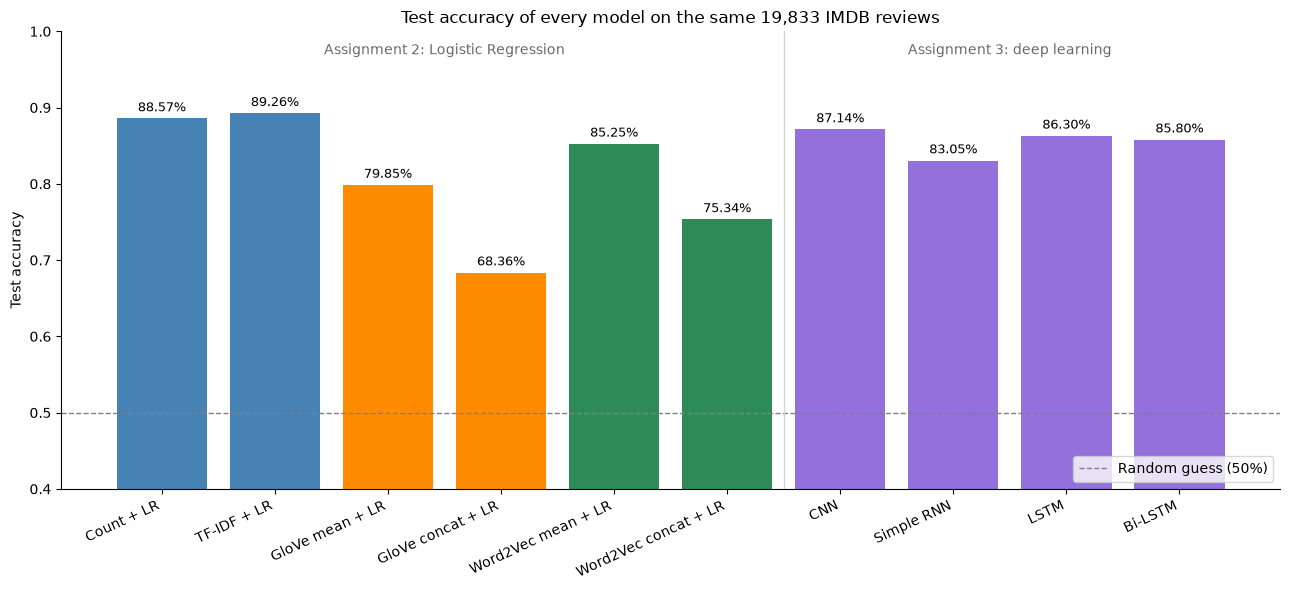

In [10]:
assignment_2 = {
    "Count + LR": 0.8857,
    "TF-IDF + LR": 0.8926,
    "GloVe mean + LR": 0.7985,
    "GloVe concat + LR": 0.6836,
    "Word2Vec mean + LR": 0.8525,
    "Word2Vec concat + LR": 0.7534,
}
all_results = {**assignment_2, **results}
names = list(all_results)
accuracies = [all_results[n] for n in names]
# Assignment 2: bag of words blue, GloVe orange, own word2vec green; this assignment: purple
colors = ["steelblue"] * 2 + ["darkorange"] * 2 + ["seagreen"] * 2 + ["mediumpurple"] * len(results)

fig, ax = plt.subplots(figsize=(13, 6))
bars = ax.bar(names, accuracies, color=colors)
ax.bar_label(bars, labels=[f"{a:.2%}" for a in accuracies], padding=3, fontsize=9)
ax.set_ylim(0.4, 1.0)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Random guess (50%)")
ax.axvline(5.5, color="lightgray", linewidth=1)
ax.text(2.5, 0.97, "Assignment 2: Logistic Regression", ha="center", color="dimgray")
ax.text(7.5, 0.97, "Assignment 3: deep learning", ha="center", color="dimgray")
ax.legend(loc="lower right")
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy of every model on the same 19,833 IMDB reviews")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

To understand the networks better, I also plot their training: accuracy on the training reviews (dashed) and on the 10% validation reviews (solid), epoch by epoch.

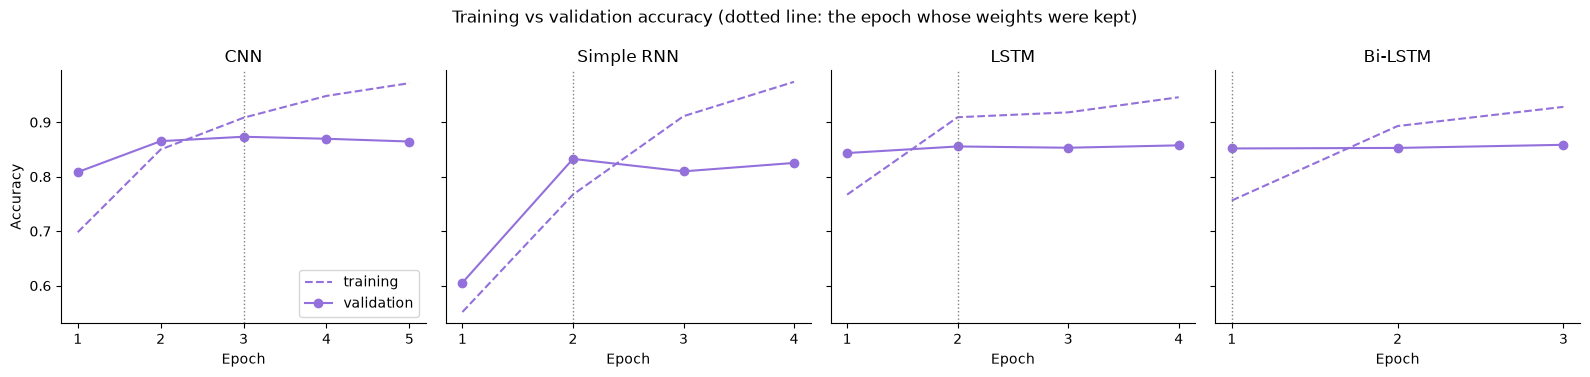

In [11]:
fig, axes = plt.subplots(1, len(histories), figsize=(16, 3.8), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    epochs = range(1, len(h["accuracy"]) + 1)
    ax.plot(epochs, h["accuracy"], "--", color="mediumpurple", label="training")
    ax.plot(epochs, h["val_accuracy"], "-o", color="mediumpurple", label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])) + 1, color="gray", linestyle=":", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")
fig.suptitle("Training vs validation accuracy (dotted line: the epoch whose weights were kept)")
plt.tight_layout()
plt.show()

### What the results show

*The y-axis starts at 40% so the differences are easier to see. The networks' accuracies are not exactly reproducible on my laptop: between two runs of the same models while I prepared this notebook, the LSTM moved by about 2 points and the others by up to 1. So differences of a point or two between the networks are within the noise.*

**Deep learning did not beat TF-IDF.** The best network, the CNN, reaches 87.1%. That is 2 points below TF-IDF + Logistic Regression (89.3%) and 1.4 points below plain word counts (88.6%). The networks also cost more to train: from about 30 seconds (simple RNN) to 3 minutes (Bi-LSTM) on my laptop's CPU. In Assignment 2, I found that sentiment in these reviews is carried mostly by specific words (*excellent*, *worst*, *waste*). A bag of words gives each of those words its own weight directly, so word order has little left to add.

**The networks memorise the training reviews within a few epochs.** In the training plots, training accuracy keeps climbing towards 93–97%, while validation accuracy levels off after one to three epochs and the validation loss, which early stopping watches, starts to rise. Early stopping kept the weights from epoch 3 for the CNN, 2 for the simple RNN and the LSTM, and 1 for the Bi-LSTM. The reason shows in the model summaries: 95–99% of each network's 1.3 million weights are in the embedding layer (20,000 words × 64 numbers), learned from scratch from only about 27,000 reviews. That is enough to memorise the reviews, not enough to learn good word meanings. Logistic Regression has the same kind of data but much less freedom.

**The CNN is the best network, and the closest to a bag of words.** Its filters detect 5-word phrases anywhere in the review, and max pooling keeps only whether each phrase appeared, not where. So it works like a bag of learned phrases. This also solves the problem of the concatenation approach in Assignment 2 (68.4% and 75.3%), where the same word in a different position was a different feature: a filter is the same at every position.

**The simple RNN is the weakest and the least stable (83.1%).** Its validation accuracy jumped from 61% to 83% and then went down and up again. Unstable training is typical of simple RNNs on long sequences: the gradients shrink or blow up as they pass back through 200 steps. In practice it relies mostly on the last words it reads.

**The LSTM fixes most of that (86.3%), and the Bi-LSTM does not add more (85.8%).** The LSTM's gates let it keep information across the review, and it gains 3 points over the simple RNN. Reading the review in both directions did not help here: the difference with the LSTM is inside the run-to-run noise, for more than twice the time per epoch. Because I kept the end of each review, the verdict is already the last thing the forward LSTM reads.

**Where the padding goes matters a lot.** With the zeros after the review, the same LSTM fell from 86.3% to 64.9%. Most reviews are shorter than 200 words, so the LSTM read the review and then a run of zeros (over a hundred for a short review), and its final state had mostly forgotten the review by the time it was classified.

**Learning the embeddings for the task beats using them as fixed features.** All four networks beat both GloVe approaches from Assignment 2 (79.9% at best), and three of them beat my own word2vec with averaging (85.3%). Here the embeddings are trained together with the classifier, so they are shaped for sentiment instead of general word similarity, and the network sees the words in order instead of an average.

**Conclusion.** With about 30,000 training reviews, TF-IDF + Logistic Regression is still the best choice: the most accurate, and the simplest. Among the networks, the CNN gives the best accuracy, and it trains in under a minute. To beat the bag of words, a network needs knowledge from outside this dataset, for example pretrained embeddings as the starting weights of the embedding layer, or a pretrained transformer such as BERT fine-tuned on the reviews.